# A planet in a gap between inclined rings

This notebook shows what [`PolarDisk`](polar_disk.md) is for. We build a synthetic scene, a star with three concentric, inclined dust rings, the outermost of them lopsided, and a planet orbiting in the gap between the second and third rings, and we observe it with VLTI-like closure-phase and squared-visibility data at several wavelengths. We then analyze the same data in two ways. First we fit the family the data came from, three Gaussian rings and a planet, with invariant priors. Then we forget that there are rings at all and ask one non-parametric component, a `PolarDisk` whose radial profile, colour and lopsidedness are Gaussian processes, to find the rings, the gap, each ring's colour and the planet by itself. By the end you should know how to write both models, how to read the radial profile $I_0(r)$ and the spectral index $\alpha(r)$ of a Gaussian-process disk against the truth, and what the Laplace evidence says about the price of the extra freedom. Everything runs at the maximum a posteriori (MAP) solution with a Laplace approximation to the posterior, with no sampling.

## The scene and the data

The star is a point source with a 6000 K blackbody spectrum, and every other component's flux is relative to it at the reference wavelength of 3 microns. The three rings are `PolarDisk`s with `GaussianRing` profiles at radii of 3, 7 and 15 mas, each with its own blackbody (1500, 900 and 600 K), so that the inner ring is bluer than the outer one. The outer ring also has an azimuthal harmonic of degree one, which makes one side of it brighter, and the planet is a `PointSource` with a 1000 K blackbody that sits in the gap between the second and third rings. The rings' radii are measured in the disk plane, not on the sky, so the planet's place in the gap has to be worked out in the plane. With a position angle of 30 degrees the major axis of the projected rings points along $(\Delta\alpha, \Delta\delta) \propto (\sin 30^\circ, \cos 30^\circ)$, and along that axis a distance on the sky equals the distance in the plane (only the perpendicular direction is foreshortened, by $\cos 50^\circ$). We put the planet on the major axis, on the side to the South-West, at an in-plane radius of 11 mas, midway between the rings at 7 and 15 mas, which gives $(\Delta\alpha, \Delta\delta) = (-5.5, -9.53)$ mas. The cell that builds the scene checks this by deprojecting the planet's offset to the disk plane and printing its radius. The rings are coplanar, so they must share an inclination and a position angle; we get that by building the whole scene in a function of the parameters that hands one `inc` and `pa` to every ring. This is the same function we will fit in the next step.

The data resemble a low-resolution L-band run with the four VLTI unit telescopes: nine channels from 2.4 to 3.6 microns, seven hour angles, so 378 squared visibilities with errors of 0.01 and 252 closure phases with errors of 0.5 degrees (567 independent data once the closure phases' correlations are accounted for). The beam of this coverage, drawn in the corner of every image below, is about 6 by 3 mas, so the 4 mas between the first two rings is of the order of one resolution element. The picture shows the truth at 3 microns with East to the left, the star saturated so that the faint outer ring can be seen, and the planet as the dot below and to the right of the centre, that is to the South and West of the star (West is on the right when East is on the left).

planet: sky separation 11.00 mas, disk-plane radius 11.00 mas (rings at 3.0, 7.0, 15.0 mas)


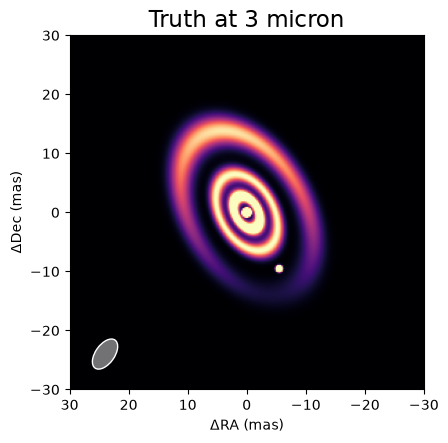

In [1]:
import sys
from pathlib import Path

root = next(
    p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").exists()
)
sys.path.insert(0, str(root / "src"))

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import numpyro.distributions as dist
from tqdm.auto import tqdm

from virgil import (
    BlackBody, GaussianRing, Harmonics, PointSource, PolarDisk,
    PolarKernel, RadialGP, System, fit, gp_priors,
)
from virgil.coverage import vlti_oidata
from virgil.imaging import beam, log_evidence
from virgil.inference import laplace_cov
from virgil.likelihood import whitened_residuals
from virgil.priors import IsotropicInclination
from virgil.plotting import (
    plot_data_model_correlation, plot_model, plot_residual_map,
)

W0 = 3.0e-6  # reference wavelength, m


def scene(inc, pa, r1, s1, f1, t1, r2, s2, f2, t2, r3, s3, f3, t3,
          h_re, h_im, dra, ddec, fp, tp):
    """Star, three coplanar rings and a planet; one inc and pa for the rings."""
    def ring(r0, sigma, flux, temp, **kw):
        return PolarDisk(GaussianRing(r0, sigma), inc=inc, pa=pa, n_r=24,
                         flux=BlackBody(flux, temp, W0), **kw)
    return System(
        star=PointSource(flux=BlackBody(1.0, 6000.0, W0)),
        ring1=ring(r1, s1, f1, t1),
        ring2=ring(r2, s2, f2, t2),
        ring3=ring(r3, s3, f3, t3, harmonics=Harmonics(re=h_re, im=h_im)),
        planet=PointSource(dra=dra, ddec=ddec, flux=BlackBody(fp, tp, W0)),
    )


truth = dict(inc=50.0, pa=30.0, r1=3.0, s1=0.8, f1=0.15, t1=1500.0,
             r2=7.0, s2=1.0, f2=0.25, t2=900.0, r3=15.0, s3=1.8, f3=0.5,
             t3=600.0, h_re=0.5, h_im=0.2, dra=-5.5, ddec=-9.526, fp=0.04,
             tp=1000.0)
truth_model = scene(**truth)


def plane_radius(dra, ddec, inc, pa):
    """Disk-plane radius of a sky offset: rotate to the major/minor axes, de-foreshorten the minor."""
    pa_r = np.radians(pa)
    major = dra * np.sin(pa_r) + ddec * np.cos(pa_r)
    minor = dra * np.cos(pa_r) - ddec * np.sin(pa_r)
    return float(np.hypot(major, minor / np.cos(np.radians(inc))))


print("planet: sky separation "
      f"{np.hypot(truth['dra'], truth['ddec']):.2f} mas, disk-plane radius "
      f"{plane_radius(truth['dra'], truth['ddec'], truth['inc'], truth['pa']):.2f} mas "
      f"(rings at {truth['r1']}, {truth['r2']}, {truth['r3']} mas)")
template = vlti_oidata(
    wavelengths_m=np.linspace(2.4e-6, 3.6e-6, 9),
    hour_angles_h=(-3, -2, -1, 0, 1, 2, 3),
    sigma_v2=0.01, sigma_cp_deg=0.5,
)
data = template.with_model(truth_model, key=jax.random.PRNGKey(0))
fig, ax = plt.subplots(figsize=(5, 4.6))
plot_model(truth_model, fov_mas=60, npix=256, ax=ax, saturate=0.99,
           beam=beam(data), title="Truth at 3 micron")
plt.show()


## The parametric fit

The truth family has 20 parameters: the shared geometry, a radius, width, flux and temperature for each ring, the two components of the outer ring's harmonic, and the planet's offset, flux and temperature. We give them invariant priors: an isotropic prior on the inclination (`IsotropicInclination`, uniform in $\cos i$, which a plain uniform prior on $i$ is not), uniform for the position angle, harmonic components and the planet's offsets, which are locations or angles, and log-uniform for the ring radii, widths, fluxes and temperatures, which are scales (a radius is a size, and rescales with the distance). We start 5 percent away from the truth, which is what a local optimizer needs, and run `fit` to the MAP solution with Levenberg-Marquardt. A coarse search of the planet's position and the ring radii would normally come first for a real target. We then take the Laplace covariance of the likelihood at the MAP point, `laplace_cov`, to get an uncertainty on each parameter and, in a few cells, the evidence.

The fit reaches a raw $\chi^2$ of 583 for 567 independent data on the quoted errors, so $\chi^2/N = 1.03$, without rescaling. Most parameters are recovered to within about one Laplace standard deviation, and the planet's position and flux are precise (0.03 mas and 3 percent), but not all: the inner ring's radius and flux are 2.4 and 3 standard deviations off (3.19 against 3.0 mas, 0.126 against 0.15), which goes with its unresolved width. The exception is the width of the innermost ring, which is not resolved: it lands on 0.15 mas, with a Laplace standard deviation of 0.38 mas that is larger than the value itself, and the truth of 0.8 mas lies within its range. A Gaussian approximation is poor for a scale parameter that is pressed against the edge of its prior, which will matter for the evidence below.

In [2]:
priors = dict(inc=IsotropicInclination(0, 85), pa=dist.Uniform(-90, 90),
              h_re=dist.Uniform(-1, 1), h_im=dist.Uniform(-1, 1),
              dra=dist.Uniform(-20, 20), ddec=dist.Uniform(-20, 20),
              fp=dist.LogUniform(0.003, 0.3), tp=dist.LogUniform(300, 3000))
for i in (1, 2, 3):
    priors |= {f"r{i}": dist.LogUniform(0.5, 25), f"s{i}": dist.LogUniform(0.1, 4),
               f"f{i}": dist.LogUniform(0.01, 2),
               f"t{i}": dist.LogUniform(300, 3000)}
start = {k: v * (1 + 0.05 * (-1) ** i) for i, (k, v) in enumerate(truth.items())}
par = fit(scene, priors, data, init=start)
names = list(priors)
x_map = np.array([float(par.values[k]) for k in names])
sigma = np.sqrt(np.diag(np.asarray(laplace_cov(x_map, names, scene, data))))
print(f"chi2 = {par.info['chi2'][0]:.0f} for N = {par.info['ndata'][0]} "
      f"independent data (chi2/N = {par.info['chi2'][0] / par.info['ndata'][0]:.2f}), "
      f"converged: {par.info['converged']}")
print(f"{'':>6}{'truth':>9}{'MAP':>9}{'Laplace sd':>12}")
for k, x, s in zip(names, x_map, sigma):
    print(f"{k:>6}{truth[k]:9.3f}{x:9.3f}{s:12.3f}")


chi2 = 583 for N = 567 independent data (chi2/N = 1.03), converged: True
          truth      MAP  Laplace sd
   inc   50.000   50.064       0.228
    pa   30.000   30.182       0.285
  h_re    0.500    0.489       0.017
  h_im    0.200    0.201       0.008
   dra   -5.500   -5.498       0.023
  ddec   -9.526   -9.512       0.028
    fp    0.040    0.040       0.001
    tp 1000.000  990.005      27.621
    r1    3.000    3.193       0.079
    s1    0.800    0.151       0.388
    f1    0.150    0.126       0.008
    t1 1500.000 1558.117      80.013
    r2    7.000    6.891       0.089
    s2    1.000    1.113       0.118
    f2    0.250    0.256       0.010
    t2  900.000  937.975      17.245
    r3   15.000   15.009       0.022
    s3    1.800    1.815       0.032
    f3    0.500    0.500       0.009
    t3  600.000  599.646       6.866


## The non-parametric fit

Now the model that does not know about rings. A single `PolarDisk` has a `RadialGP` profile on 48 nodes between 1.5 and 24 mas, the log of $I_0(r)$ being a Matérn Gaussian process with a correlation length of 1.5 mas. Its harmonics are `Harmonics(degree=1, prior=PolarKernel(...))`, a first-order lopsidedness whose amplitude and phase are themselves Gaussian processes in the radius, and its `spectral_index` is another `RadialGP`, so that the intensity at radius $r$ and wavelength $\lambda$ is $I_0(r)(\lambda/\lambda_0)^{\alpha(r)}$. The harmonic's low degree is what stops the disk from absorbing the planet, which is a compact, strongly asymmetric source, and the planet and star keep their parametric forms. Every Gaussian-process latent has a standard-normal prior, which `gp_priors` writes for us. The hyperparameters are fixed at values chosen by eye (a later cell compares two values of the profile's length scale by the evidence), and we start the geometry, the disk's total flux and the planet from the parametric fit of the previous step, which are held or started there rather than refitted from scratch. The geometry is not refitted: the inclination and position angle are the MAP values above, which have uncertainties of 0.2 and 0.3 degrees.

The inner edge of the Gaussian process is set at 1.5 mas, which is below the first ring but a little under the beam. An earlier try with the inner edge at 0.5 mas, below any resolution, let the disk put about a quarter of its light into an unresolved core that traded off against the star's flux, which the data cannot tell apart; the visibilities were fitted just as well. We keep the edge at 1.5 mas, so the fit cannot hide light in the centre, but the profile still rises steeply at the innermost nodes (see the figures below), so some freedom to trade light with the star remains, and the disk flux is about 8 percent above the truth. The fit reaches $\chi^2/N = 1.20$ on the quoted errors, a little worse than the parametric model's 1.03, and recovers the planet's position within 0.05 mas and its flux (0.043 of the star's) to within 8 percent of the parametric value of 0.040. The disk's flux is 0.96, against 0.88 for the fitted rings and a truth of 0.90.

In [3]:
v = par.values
r_in, r_out = 1.5, 24.0
disk = PolarDisk(
    RadialGP(r_in, r_out, sigma=3.0, ell=1.5, n=48),
    harmonics=Harmonics(degree=1, prior=PolarKernel(
        ell_r=3.0, ell_theta=8.0, sigma=0.5, n=10, r_in=r_in, r_out=r_out)),
    spectral_index=RadialGP(r_in, r_out, sigma=3.0, ell=2.0, n=22),
    wavel0=W0, inc=v["inc"], pa=v["pa"], n_r=48,
    flux=v["f1"] + v["f2"] + v["f3"],
)
gp = System(
    star=PointSource(flux=BlackBody(1.0, 6000.0, W0)),
    disk=disk,
    planet=PointSource(dra=v["dra"], ddec=v["ddec"],
                       flux=BlackBody(v["fp"], v["tp"], W0)),
)
gp_priors_ = gp_priors(gp) | {
    "disk.flux": dist.LogUniform(0.05, 5.0),
    "planet.dra": dist.Uniform(-20, 20), "planet.ddec": dist.Uniform(-20, 20),
    "planet.flux.ratio": dist.LogUniform(0.003, 0.3),
    "planet.flux.temperature": dist.LogUniform(300, 3000),
}
gpfit = fit(gp, gp_priors_, data)
gv = gpfit.values
print(f"chi2 = {gpfit.info['chi2'][0]:.0f} for N = {gpfit.info['ndata'][0]} "
      f"independent data (chi2/N = {gpfit.info['chi2'][0] / gpfit.info['ndata'][0]:.2f}), "
      f"converged: {gpfit.info['converged']}, {gpfit.info['steps']} steps")
print(f"planet offset (dra, ddec) = ({gv['planet.dra']:.2f}, {gv['planet.ddec']:.2f}) mas "
      f"(parametric: {v['dra']:.2f}, {v['ddec']:.2f}; "
      f"truth {truth['dra']:.2f}, {truth['ddec']:.2f})")
print(f"planet flux at 3 micron = {gv['planet.flux.ratio']:.3f} of the star "
      f"(parametric: {v['fp']:.3f}; truth 0.040)")
print(f"disk flux at 3 micron = {gv['disk.flux']:.2f} "
      f"(parametric rings: {v['f1'] + v['f2'] + v['f3']:.2f}; truth 0.90)")


chi2 = 680 for N = 567 independent data (chi2/N = 1.20), converged: True, 57 steps
planet offset (dra, ddec) = (-5.53, -9.51) mas (parametric: -5.50, -9.51; truth -5.50, -9.53)
planet flux at 3 micron = 0.043 of the star (parametric: 0.040; truth 0.040)
disk flux at 3 micron = 0.96 (parametric rings: 0.88; truth 0.90)


## The evidence, parametric against Gaussian process

How much should we believe the extra freedom? The Laplace evidence is $\log Z \approx -\tfrac12\chi^2 + \log\pi(\hat\theta) + \tfrac d2\log 2\pi + \tfrac12\log\det\Sigma$ for the parametric model, with $\Sigma$ the Laplace covariance, and `log_evidence` computes the equivalent expression for the Gaussian-process latents, $-\tfrac12\chi^2 - \tfrac12|z|^2 - \tfrac12\log\det(I + J^TJ)$. Both are in the same normalization of the data's likelihood, so only differences between them mean anything. Two caveats apply, and they pull in opposite directions. The Gaussian-process evidence is conditional on its fixed hyperparameters, and `log_evidence` holds every non-latent parameter (the disk flux, the planet's four parameters, and, since we took it from the parametric fit, the geometry, which was tuned on these same data) at its MAP value with no prior or Occam factor. That is a profile likelihood over those parameters, not a marginal one, and each parameter left unmarginalized would have contributed a negative term of a few nats, so this caveat favours the Gaussian process. The parametric evidence marginalizes all 20 parameters, and its family contains the truth, which is of course not something a real analysis can assume, so this second caveat favours the parametric model. The two do not cancel in any known amount (in the run below the parametric log $Z$ is higher by about 63 nats, and the size of this gap should not be read literally), and the gap between the two numbers is therefore not a calibrated Bayes factor, even though the Laplace approximation is itself rough for the parameter that presses on its prior edge. We also compare the profile's correlation length of 1.5 mas with a longer one of 4 mas, a comparison between two Gaussian-process fits with the same held parameters, which is the cleaner use of this number and is how MacKay's evidence framework chooses a hyperparameter.

In [4]:
gpm = gpfit.model
# Laplace evidence of the parametric fit: log L + log prior + (d/2) log 2 pi
# + (1/2) log det Sigma, in the same data normalization as log_evidence.
cov = np.asarray(laplace_cov(x_map, names, scene, data))
chi2_par = float(np.sum(np.asarray(whitened_residuals(par.model, data)) ** 2))
log_prior = sum(float(priors[k].log_prob(par.values[k])) for k in names)
logz_par = (-0.5 * chi2_par + log_prior + 0.5 * len(names) * np.log(2 * np.pi)
            + 0.5 * np.linalg.slogdet(cov)[1])
logz = {}
for ell in tqdm((1.5, 4.0), desc="profile length scale"):
    f = gpfit if ell == 1.5 else fit(gp.set("disk.profile.ell", ell), gp_priors_, data)
    logz[ell] = float(log_evidence(f, data, path="disk"))
print(f"parametric (20 parameters, Laplace-marginalized): log Z = {logz_par:8.1f}")
for ell, z in logz.items():
    print(f"GP (other parameters at MAP), profile length scale {ell:4.2f} mas: log Z = {z:8.1f}"
          + ("  (used below)" if ell == 1.5 else ""))


profile length scale:   0%|          | 0/2 [00:00<?, ?it/s]

parametric (20 parameters, Laplace-marginalized): log Z =   -386.1
GP (other parameters at MAP), profile length scale 1.50 mas: log Z =   -448.8  (used below)
GP (other parameters at MAP), profile length scale 4.00 mas: log Z =   -448.6


## What the data taught the Gaussian process

The evidence comparison is not like for like (see the caveats above): the parametric log $Z$ is $-386$ and the Gaussian process's is $-449$, but it is unsurprising that a model that is told where the rings are is not beaten by one that is not. The two profile length scales, 1.5 and 4 mas, have the same evidence to within 0.2 nats, so the data do not choose between them and the choice of 1.5 mas is a prior one. What the Gaussian process buys is not evidence but not having to know. The two panels compare the prior of the profile and of the spectral index, a band of the 16 to 84 percent range of draws from the Gaussian-process prior at the fixed hyperparameters, with a band of draws from the Laplace posterior of the latents, $\mathcal N(z_0, (I + J^TJ)^{-1})$, the same approximation that the evidence uses. Only the latents vary in the posterior bands: the geometry, the planet and the disk flux are held at their MAP values, so the bands are narrower than the full posterior would be. The profile has gone from an unstructured prior that spans four decades to a posterior that has three bumps and a gap, plus a steep rise at the innermost nodes that is the edge effect discussed above, and the spectral index from a wide band to a band that traces a step, with a lower value at the inner radii and a higher one in the outer ring.

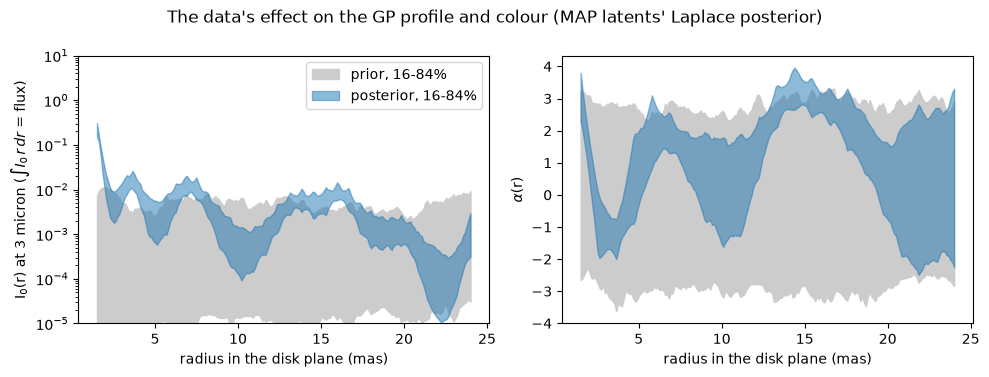

In [5]:
latents = ["disk.profile.z", "disk.harmonics.z", "disk.spectral_index.z"]
z0 = [np.asarray(gpm.get(p)) for p in latents]
flat0 = jnp.concatenate([jnp.ravel(z) for z in z0])


def residuals(flat):
    m, k = gpm, 0
    for p, z in zip(latents, z0):
        m = m.set(p, flat[k:k + z.size].reshape(z.shape))
        k += z.size
    return whitened_residuals(m, data)


# Laplace posterior of the latents, N(z0, (I + J^T J)^-1), as log_evidence uses
jac = np.asarray(jax.jacfwd(residuals)(flat0))
chol = np.linalg.cholesky(np.linalg.inv(np.eye(flat0.size) + jac.T @ jac))
rng = np.random.default_rng(0)
draws = np.asarray(flat0) + rng.standard_normal((200, flat0.size)) @ chol.T

rg = np.linspace(r_in, r_out, 200)


def profile_alpha(flat):
    """Surface brightness (unit integral times the disk flux), alpha(r), |I_1|."""
    m, k = gpm, 0
    for p, z in zip(latents, z0):
        m = m.set(p, flat[k:k + z.size].reshape(z.shape))
        k += z.size
    i0 = m.disk.profile.intensity(rg, 0.1)
    i0 = i0 / jnp.trapezoid(i0 * rg, rg) * m.disk.flux
    return (i0, m.disk.spectral_index(rg),
            jnp.abs(m.disk.harmonics.image_harmonics(rg)[1]))


post_i0, post_al, post_h1 = (
    np.asarray(x) for x in jax.vmap(profile_alpha)(jnp.asarray(draws))
)
key = jax.random.PRNGKey(1)
prior_i0 = np.asarray(gpm.disk.profile.draws(key, 200, r=rg, positive=True))
prior_i0 = prior_i0 / np.trapezoid(prior_i0 * rg, rg, axis=1)[:, None] * float(gpm.disk.flux)
prior_al = np.asarray(gpm.disk.spectral_index.draws(key, 200, r=rg))
band = lambda x: np.percentile(x, [16, 84], axis=0)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, pr, po, label in zip(axes, (prior_i0, prior_al), (post_i0, post_al),
                             (r"I$_0$(r) at 3 micron ($\int I_0\,r\,dr$ = flux)", r"$\alpha$(r)")):
    ax.fill_between(rg, *band(pr), color="0.8", label="prior, 16-84%")
    ax.fill_between(rg, *band(po), color="C0", alpha=0.5, label="posterior, 16-84%")
    ax.set_xlabel("radius in the disk plane (mas)")
    ax.set_ylabel(label)
axes[0].set_yscale("log")
axes[0].set_ylim(1e-5, 1e1)
axes[0].legend()
fig.suptitle("The data's effect on the GP profile and colour (MAP latents' Laplace posterior)")
plt.tight_layout()
plt.show()


## Truth, parametric fit and deconvolution side by side

The top row shows the three images at 3 microns on the same colour scale, with the beam in the corner; the second row shows the two fits minus the truth as plain signed residuals, not z-scores, since the MAP images have no uncertainty, on a colour scale that is symmetric about zero. The three middle panels compare the radial profile, the colour and the lopsidedness with the truth. The truth for the profile is the sum of the three Gaussians in r, centred on the ring radii and normalized so that $\int I_0\, r\,dr$ is the flux, as for the Gaussian process, for the colour it is the intensity-weighted logarithmic slope of the three blackbodies at 3 microns, and for the lopsidedness it is the outer ring's first harmonic weighted by that ring's share of the light at each radius. The blue bands are the Laplace posterior of the latents from the previous cell. The spectra panel integrates the Gaussian-process disk's flux, $I_0(r)(\lambda/\lambda_0)^{\alpha(r)}$ over three radial windows (inside 5.3 mas, between 5.3 and 10 mas, and outside 10 mas) and sets each against the blackbody of the corresponding ring. The bottom row shows the residuals of both fits, divided by the quoted errors, for the squared visibilities and the closure phases, with the root mean square of each in the legend.

The Gaussian process puts bumps at about 3.5, 7 and 15 mas against the true 3, 7 and 15 mas, so the ring radii agree to within one resolution element, and it cuts a gap between the second and third rings, with a minimum near 10 mas in which the planet sits at 11 mas in the disk plane, a little nearer the third ring than the profile's minimum. It reproduces the radial contrast of the profile to within its bands, including the steep fall beyond 20 mas, where the data have no constraint and the band widens to the prior. The spectral index follows the truth for the outer ring, which is red with a slope near 3, and the band is wide in the middle ring, whose colour is only weakly determined. The inner ring is where it fails: the index band at 3 to 4 mas is consistent with the truth (about $-1.7$), but the steep rise of the index at the innermost radii is an edge effect of the Gaussian process, where the data have little leverage, and it makes the flux-weighted spectrum of the innermost window rise with wavelength, where the true ring 1 falls, so the Gaussian process gets the sign of the inner ring's colour wrong in the spectra panel. The third middle panel shows the lopsidedness, the first harmonic's amplitude relative to the azimuthal mean: it is near 0.4 beyond 10 mas, as in the truth, and close to zero between 5 and 9 mas, but the band is wide (up to about 0.3) at the innermost radii. The recovered spectra are of the right order and ordering for the middle and outer rings and the planet but, as the dashed lines show, a power law in wavelength over a band with this much curvature only approximates a blackbody, and the inner ring's spectrum is wrong, as above. In the residual maps, which are dominated by the centre, the residual of the Gaussian-process image is about three times that of the parametric one (the scales differ), and both lie within the inner ring and on the star, with nothing visible at the outer ring or the planet.

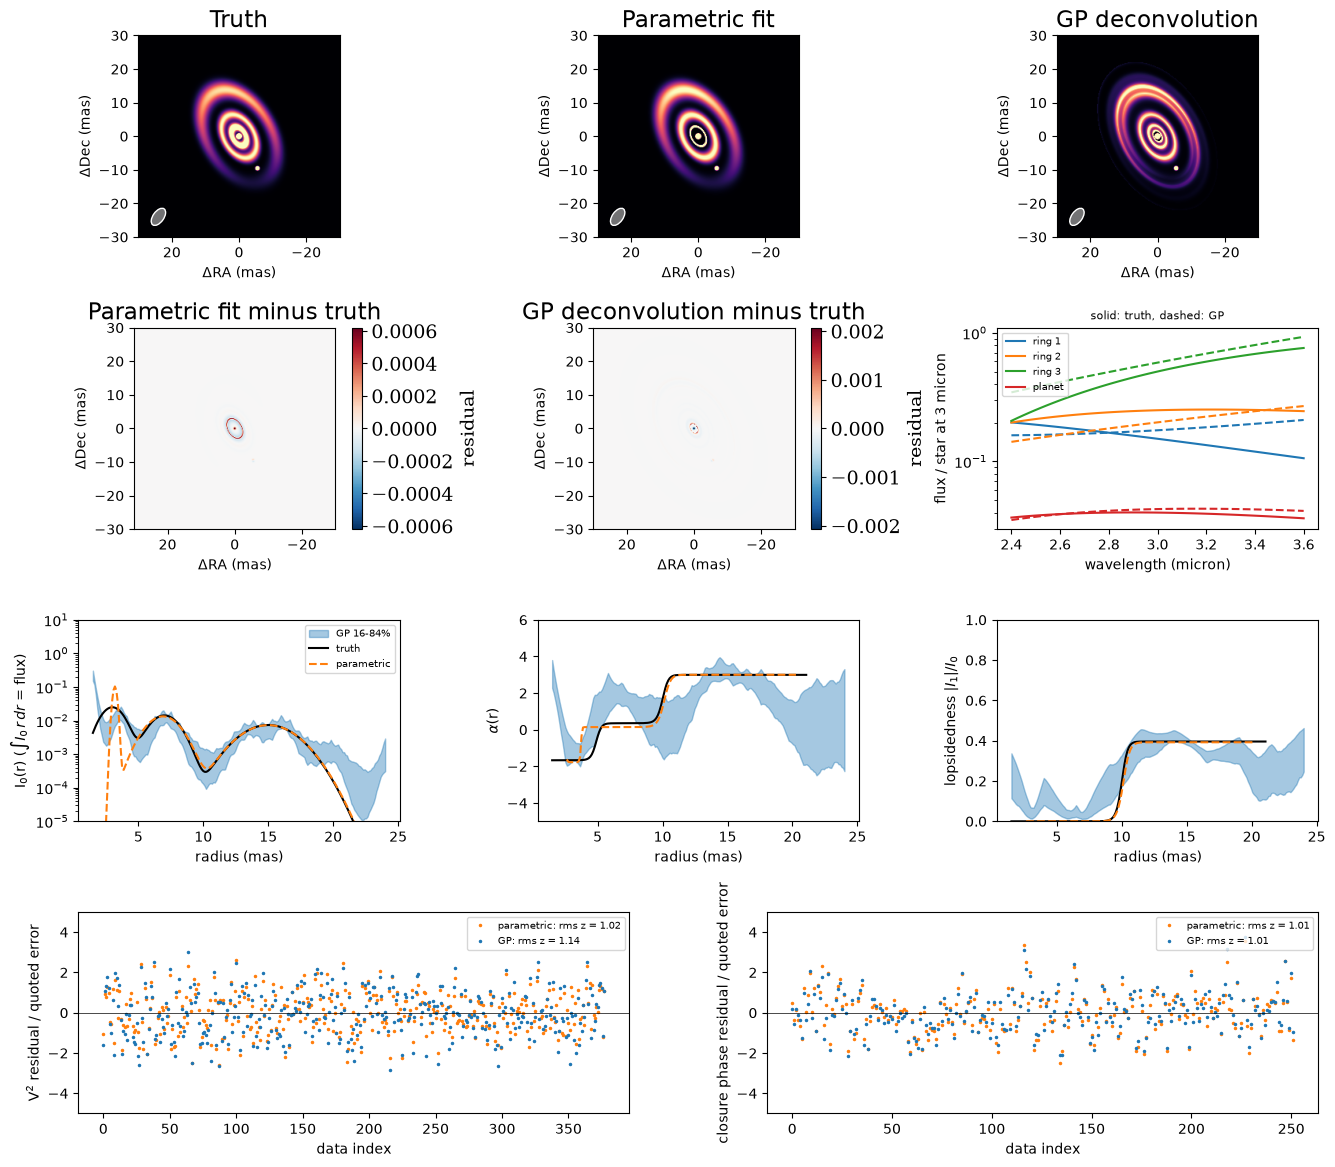

In [6]:
par_model, bm = par.model, beam(data)
y, err = data.flatten_data()
n_vis = np.asarray(data.vis).size
lam = np.linspace(2.4e-6, 3.6e-6, 50)
alpha_of = lambda t: float(jax.grad(lambda l: jnp.log(BlackBody(1.0, t, W0)(l)))(W0) * W0)


def truth_profile(r, p):
    """I0(r) at 3 micron, the intensity-weighted alpha(r) and the harmonic |I_1|(r).

    Each ring is exp[-(r - r_i)^2 / 2 s_i^2], as GaussianRing has it, normalized by
    sqrt(2 pi) s_i r_i so that the integral of I0 r dr is the ring's flux (exact to
    <0.1 percent here, where r_i >> s_i).
    """
    g = [p[f"f{i}"] * np.exp(-0.5 * ((r - p[f"r{i}"]) / p[f"s{i}"]) ** 2)
         / (np.sqrt(2 * np.pi) * p[f"s{i}"] * p[f"r{i}"]) for i in (1, 2, 3)]
    a = [alpha_of(p[f"t{i}"]) for i in (1, 2, 3)]
    h3 = abs(np.asarray(Harmonics(re=p["h_re"], im=p["h_im"]).image_harmonics())[1])
    tot = sum(g) + 1e-30
    return sum(g), sum(gi * ai for gi, ai in zip(g, a)) / tot, h3 * g[2] / tot


fig = plt.figure(figsize=(16, 14))
grid = fig.add_gridspec(4, 6, hspace=0.45, wspace=1.5)
models = [(truth_model, "Truth"), (par_model, "Parametric fit"), (gpm, "GP deconvolution")]
for j, (m, name) in enumerate(models):
    plot_model(m, fov_mas=60, npix=256, ax=fig.add_subplot(grid[0, 2 * j:2 * j + 2]),
               saturate=0.99, beam=bm, title=name)
true_image = truth_model.render(npix=256, fov_mas=60)
for j, (m, name) in enumerate(models[1:]):
    plot_residual_map(np.asarray(m.render(npix=256, fov_mas=60) - true_image), 60,
                      ax=fig.add_subplot(grid[1, 2 * j:2 * j + 2]),
                      title=f"{name} minus truth")
ax = fig.add_subplot(grid[2, 0:2])
i_t, a_t, h_t = truth_profile(rg, truth)
i_p, a_p, h_p = truth_profile(rg, dict(par.values))
ax.fill_between(rg, *band(post_i0), color="C0", alpha=0.4, label="GP 16-84%")
ax.plot(rg, i_t, "k", label="truth")
ax.plot(rg, i_p, "C1--", label="parametric")
ax.set(yscale="log", ylim=(1e-5, 1e1), xlabel="radius (mas)", ylabel=r"I$_0$(r) ($\int I_0\,r\,dr$ = flux)")
ax.legend(fontsize=7)
ax = fig.add_subplot(grid[2, 2:4])
ax.fill_between(rg, *band(post_al), color="C0", alpha=0.4)
ax.plot(rg, np.where(i_t > 1e-3 * i_t.max(), a_t, np.nan), "k")
ax.plot(rg, np.where(i_p > 1e-3 * i_p.max(), a_p, np.nan), "C1--")
ax.set(xlabel="radius (mas)", ylabel=r"$\alpha$(r)", ylim=(-5, 6))
ax = fig.add_subplot(grid[2, 4:6])
ax.fill_between(rg, *band(post_h1), color="C0", alpha=0.4)
ax.plot(rg, np.where(i_t > 1e-3 * i_t.max(), h_t, np.nan), "k")
ax.plot(rg, np.where(i_p > 1e-3 * i_p.max(), h_p, np.nan), "C1--")
ax.set(xlabel="radius (mas)", ylabel=r"lopsidedness $|I_1|/I_0$", ylim=(0, 1))
ax = fig.add_subplot(grid[1, 4:6])
nodes, w = (np.asarray(x) for x in gpm.disk.profile.quadrature())
frac, al = w / w.sum(), np.asarray(gpm.disk.spectral_index(nodes))
for i, (lo, hi) in enumerate([(0, 5.3), (5.3, 10.0), (10.0, 99)]):
    inside = (nodes >= lo) & (nodes < hi)
    f_gp = float(gpm.disk.flux) * (frac[inside, None] * (lam / W0) ** al[inside, None]).sum(0)
    t_i = BlackBody(truth[f"f{i + 1}"], truth[f"t{i + 1}"], W0)(lam)
    ax.plot(lam * 1e6, t_i, f"C{i}", label=f"ring {i + 1}")
    ax.plot(lam * 1e6, f_gp, f"C{i}--")
ax.plot(lam * 1e6, BlackBody(truth["fp"], truth["tp"], W0)(lam), "C3", label="planet")
ax.plot(lam * 1e6, BlackBody(gv["planet.flux.ratio"], gv["planet.flux.temperature"], W0)(lam), "C3--")
ax.set(xlabel="wavelength (micron)", ylabel="flux / star at 3 micron", yscale="log")
ax.set_title("solid: truth, dashed: GP", fontsize=8)
ax.legend(fontsize=7)
for col, (sl, label) in enumerate([(slice(0, n_vis), r"V$^2$"), (slice(n_vis, None), "closure phase")]):
    ax = fig.add_subplot(grid[3, 3 * col:3 * col + 3])
    for m, name, c in [(par_model, "parametric", "C1"), (gpm, "GP", "C0")]:
        z = np.asarray(data.residuals(data.model(m)))[sl] / err[sl]
        ax.plot(z, ".", ms=3, color=c, label=f"{name}: rms z = {np.sqrt(np.mean(z**2)):.2f}")
    ax.axhline(0, color="k", lw=0.5)
    ax.set(xlabel="data index", ylabel=f"{label} residual / quoted error", ylim=(-5, 5))
    ax.legend(fontsize=7, loc="upper right")
plt.show()


## Data against model

For completeness, the model squared visibilities and closure phases against the data, with the errors on the data and the one-to-one line, for both fits. Since the observables are the same 378 and 252 numbers whichever model made them, the two sets of points lie on top of each other and on the line, from the lowest visibilities at about 5 percent to the highest at about 65 percent; the model is in no part of the range systematically away from the data. The residual plot above is the more sensitive test, in which the Gaussian process has a squared-visibility root mean square of 1.14 against the parametric model's 1.02.

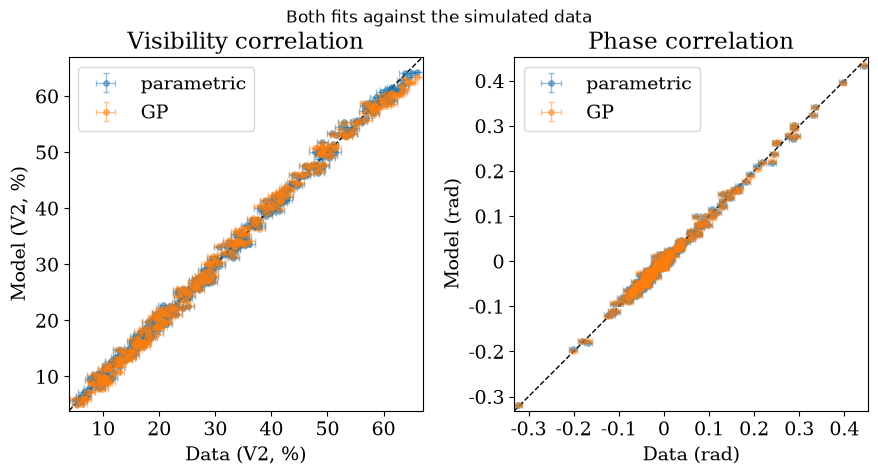

In [7]:
def summary(m):
    pred = np.asarray(data.model(m))
    return {"vis_mean": pred[:n_vis], "vis_std": 0 * pred[:n_vis],
            "phi_mean": pred[n_vis:], "phi_std": 0 * pred[n_vis:]}


fig, _ = plot_data_model_correlation(
    data, {"parametric": summary(par_model), "GP": summary(gpm)}, figsize=(9, 4.5))
fig.suptitle("Both fits against the simulated data", y=1.03)
plt.show()


## Summary

A non-parametric `PolarDisk` found the rings, the gap, the outer ring's lopsidedness and the planet from the same 630 numbers that a parametric fit of the true family used, without being told that there are three rings. The ring radii agree with the truth to within about a resolution element, the colour of the inner and outer rings agrees with the blackbody slopes, and the planet's position and flux agree with the parametric fit; the exception is the inner ring's colour, which is spoiled by the edge of the profile. The costs are visible too: the fit is a little worse on the quoted errors ($\chi^2/N$ of 1.20 against 1.03), the colour of the middle ring is poorly determined, a power law in wavelength only approximates a blackbody, and the inner edge of the Gaussian process needed to stay above the resolution. The Laplace log $Z$ is 63 nats higher for the parametric model, but the comparison is only indicative, since the Gaussian process's evidence holds its non-latent parameters at their MAP values, which favours it, while the parametric family contains the truth, which favours the other. For real data, the sensible use of the two is together: the Gaussian process to find the structure and propose a parametric family, and the parametric fit, with its evidence, to confirm and measure it. The Gaussian-process hyperparameters here were fixed; sampling them, with NUTS and the whitened latents, is the next step and is not done in this notebook.

## As a pipeline

Both fits above can be run with [`DiskPipeline`](pipeline.md), which is provisional. It fixes the order of the steps and writes a run folder that reloads without recomputing. The simulated `data` are its `load` stage. A grid over the inclination and position angle with a single ring, then a fit of that ring, is its `geometry` stage; the geometry it finds is the starting point of the parametric fit and the geometry that the Gaussian process holds. The `profile` and `compare` stages fit the model and choose among its variants. `model="rings"` adds Gaussian rings, each sharing the inclination and position angle, until the BIC stops improving, and keeps the count of least BIC; `model="gp"` (the default) fits a `RadialGP` profile with `Harmonics` of degree one and a spectral index that is itself a Gaussian process, at each length scale of a grid, and keeps the length of largest Laplace evidence. The cell below sets only the choices made in this notebook: the 6000 K blackbody star, the 3 micron reference wavelength, an outer radius of 24 mas (the default is half the field of view, which is too small for the 15 mas ring), and the companion search, which is off by default. The length-scale grid is $\ell/\sqrt{3}$ of 0.4, 1 and 2 half-fringes of the longest baseline, which includes the 1.5 mas used above. Neither run samples: `posterior=True` would run NUTS with the geometry released.

The pipelines find the rings and the planet without being told how many there are or where. Their priors are the pipeline's group-invariant ones (a flux, radius and width are log-uniform, the inclination is uniform in $\cos i$, the position angle an angle vector), and each ring's colour is a power law in wavelength, which only approximates the blackbodies that made the data. So the numbers agree with the hand-written fits to within the Laplace uncertainties, not exactly. They report $\chi^2/N$ on the quoted errors as the first check of each run.

In [ ]:
from tempfile import mkdtemp

from virgil.pipeline import DiskPipeline

settings = dict(
    r_out_mas=24.0,
    star_temperature_k=6000.0,
    wavel0_m=W0,
    companion=True,
    max_rings=4,
    ell_halffringes=[0.4, 1.0, 2.0],
    quicklook_execute=False,
)
rings_res = DiskPipeline(
    data, "rings", output=f"{mkdtemp()}/rings_run", **settings
).run()
gp_res = DiskPipeline(
    data, "gp", output=f"{mkdtemp()}/gp_run", **settings
).run()

print(rings_res.describe())
print()
print(gp_res.describe())

In [ ]:
from virgil.pipeline.disk import plot_summary

plot_summary(gp_res.model(), data, r_out_mas=24.0, r_in_mas=gp_res.summary["model"]["r_in_mas"])
plt.show()

In [ ]:
rings_s, gp_s = rings_res.summary, gp_res.summary
best_rings = next(
    row for row in rings_s["compare"]["rows"] if row["n"] == rings_s["disk"]["n_rings"]
)
fitted = best_rings["radii"]
for i in (1, 2, 3):
    k = int(np.argmin([abs(r - truth[f"r{i}"]) for r in fitted]))
    sd = best_rings["sd"][f"r{k + 1}"] or 0.0
    print(f"ring {i}: truth r={truth[f'r{i}']:.2f}  pipeline r={fitted[k]:.2f} +- {sd:.2f} mas")
    # The rings are found within a few Laplace standard deviations of the truth.
    assert abs(fitted[k] - truth[f"r{i}"]) < 4 * sd + 0.3
assert rings_s["disk"]["n_rings"] >= 3

for name, s, tol in (("rings", rings_s, 0.1), ("gp", gp_s, 0.3)):
    planet = s["disk"]["companion"]
    assert planet is not None, name
    print(f"{name:>5} planet: dra={planet['dra_mas']:.2f}  ddec={planet['ddec_mas']:.2f}  "
          f"flux={planet['flux']:.3f}  (truth {truth['dra']}, {truth['ddec']}, {truth['fp']})")
    sd = best_rings["sd"] if name == "rings" else {}
    assert abs(planet["dra_mas"] - truth["dra"]) < 4 * (sd.get("dra") or 0.0) + tol
    assert abs(planet["ddec_mas"] - truth["ddec"]) < 4 * (sd.get("ddec") or 0.0) + tol

best_chi2 = lambda s: s["chi2"]["reduced"][s["disk"]["best"]]
print(f"chi2/N: rings {best_chi2(rings_s):.2f} (tutorial 1.03), gp {best_chi2(gp_s):.2f} (tutorial 1.20)")
assert best_chi2(rings_s) < 1.3
assert best_chi2(gp_s) < 1.6
assert rings_res.checks[0].name == gp_res.checks[0].name == "chi2_reduced"
